# Validate the market core

The market without the Studio: only `core/` (`core.config`, `core.market`,
`core.grid`), the same
calls a notebook or an RL trainer makes. Every step is shown as plain tables, so
when something looks wrong it is the core, not the UI.

1. **Scenario**: network, day, participants
2. **Inputs**: what each participant generates and needs per step
3. **One step**: orders, then each clearing stage, then settlement
4. **The whole day**: one row per step
5. **Checks**: rules every step must keep (a failing check names the step)
6. **Experiments**: change one setting, compare the day

Run top to bottom. Change the scenario in section 1 and run again.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core" / "market").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from core.config import placement
from core.config.scenario import Scenario
from core.grid.powerflow import SimBenchGrid
from core.market.clearing import DSO_ID
from core.market.lem import LocalEnergyMarket, StepRecord

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1. Scenario

Everything the market is built from. The defaults are `Scenario()`'s; change
any field here. `placement.place_all(scenario, kinds)` puts one participant on
every bus of the given kinds: what the bus carries, e.g. `"load"`, `"load+pv"`
or `"load+storage"`. `placement.kind_counts(scenario)` lists the kinds the
network has.

The scenario is saved to `config/scenarios/validate_market.json`, the
format the Studio keeps its scenario in. In the Studio, click **Scenario: …**
in the header and open `validate_market.json` to play the same scenario on
the Step page; `tests/test_studio_matches_core.py` checks both give the same day.

In [2]:
from core.config import store
from core.config.scenario import BatterySetup, ParticipantSetup, Scenario

net = "LV1.101 "
scenario = Scenario(name="validate_market")
scenario.market.partner_preference = True
scenario.participants = [
    ParticipantSetup("P1", net + "Bus 7", [net + "Load 9", net + "SGen 1"], BatterySetup(10)),
    ParticipantSetup("P2", net + "Bus 8", [net + "Load 2", net + "SGen 4"]),
    ParticipantSetup("P3", net + "Bus 1", [net + "Load 8"]),
    ParticipantSetup("P4", net + "Bus 5", [net + "Load 13"]),
    ParticipantSetup("P5", net + "Bus 12", [net + "Load 10"], BatterySetup(10)),
]

# The same scenario for the Studio (header: Scenario: … > Open). Read back,
# so the notebook runs the file.
SCENARIO_FILE = ROOT / "config" / "scenarios" / "validate_market.json"
store.save(scenario, SCENARIO_FILE)
scenario = store.load(SCENARIO_FILE)
print(f"Saved to {SCENARIO_FILE.relative_to(ROOT)}")

Saved to notebooks\scenarios\validate_market.json


In [3]:
def participants_table(scenario: Scenario) -> pd.DataFrame:
    """One row per participant: bus, what it took over, its battery."""
    kinds = {
        e.id: e.element_type
        for elements in placement.elements_by_bus(scenario).values()
        for e in elements
    }
    rows = []
    for p in scenario.participants:
        b = p.battery
        rows.append(
            {
                "id": p.id,
                "bus": p.bus,
                "loads": sum(kinds.get(e) == "load" for e in p.owns),
                "generators": sum(kinds.get(e) == "sgen" for e in p.owns),
                "storage": sum(kinds.get(e) == "storage" for e in p.owns),
                "battery_kwh": b.capacity_kwh if b else 0.0,
                "soc_start": b.initial_soc if b else None,
                "soc_window": f"{b.min_soc}-{b.max_soc}" if b else None,
            }
        )
    return pd.DataFrame(rows).set_index("id")


participants_table(scenario)

,bus,loads,generators,storage,battery_kwh,soc_start,soc_window
id,,,,,,,
P1,LV1.101 Bus 7,1,1,0,10.0,0.5,0.1-0.9
P2,LV1.101 Bus 8,1,1,0,0.0,NaN,None
P3,LV1.101 Bus 1,1,0,0,0.0,NaN,None
P4,LV1.101 Bus 5,1,0,0,0.0,NaN,None
P5,LV1.101 Bus 12,1,0,0,10.0,0.5,0.1-0.9


## 2. Inputs per step

Generation and demand in kWh per step, read from the SimBench profiles of the
elements each participant took over. **Net = generation − demand**: positive
means the participant has energy to sell (or to put in its battery), negative
means it needs energy.

A peer-to-peer trade needs a seller **and** a buyer in the same step. The last
table counts them before any battery is used.

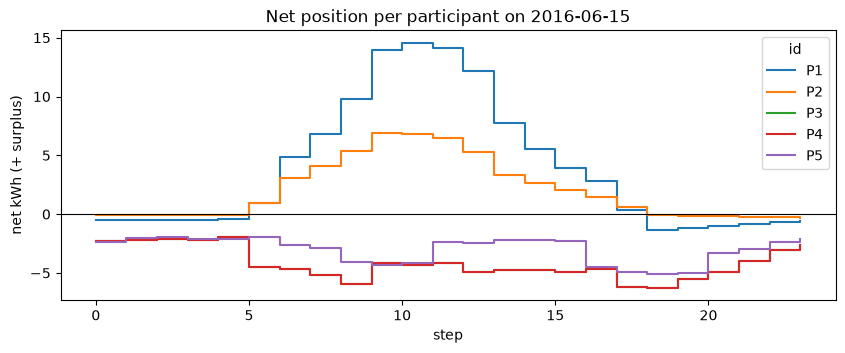

step,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
with surplus,0.000,0.000,0.000,0.000,0.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.00,2.000,0.000,0.000,0.000,0.000,0.000,0.000
with deficit,5.000,5.000,5.000,5.000,5.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.00,3.000,5.000,5.000,5.000,5.000,5.000,5.000
total net kWh,-7.559,-6.949,-6.772,-7.013,-6.477,-9.062,-4.054,-2.294,-0.855,8.288,8.529,9.955,5.168,-0.616,-3.554,-6.157,-9.57,-16.384,-19.024,-17.355,-14.308,-12.067,-9.381,-8.362


In [4]:
def inputs_table(lem: LocalEnergyMarket) -> pd.DataFrame:
    """Generation, demand and net per step and participant (kWh)."""
    rows = []
    for t in range(lem.n_steps):
        for pid, p in lem.participants.items():
            g, d = p.generation_kwh[t], p.demand_kwh[t]
            rows.append({"step": t, "id": pid, "gen": g, "dem": d, "net": p.net_kwh(t)})
    return pd.DataFrame(rows)


lem = LocalEnergyMarket(scenario)
lem.reset()
inputs = inputs_table(lem)
net = inputs.pivot(index="step", columns="id", values="net")

fig, ax = plt.subplots(figsize=(10, 3.5))
net.plot(ax=ax, drawstyle="steps-post")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("net kWh (+ surplus)")
ax.set_title(f"Net position per participant on {scenario.grid.day}")
plt.show()

pd.DataFrame(
    {
        "with surplus": (net > 1e-9).sum(axis=1),
        "with deficit": (net < -1e-9).sum(axis=1),
        "total net kWh": net.sum(axis=1),
    }
).T

## 3. One step, part by part

The same five parts as the Studio's Step page: orders, stage 1 (preferences),
stage 2 (double auction), stage 3 (DSO), settlement with the power flow. Set
`STEP` to the hour to look at.

Every peer-to-peer trade carries what the DSO assessed: its distance along the
lines (d_ij), its transmission loss (eq. 18, recorded only: the power flow has
the physical losses) and its grid fee (eq. 8), split between buyer and seller
when the fees are charged. After settlement come the DSO's step (balance,
eq. 7) and each participant's reputation update (eq. 12 and its decay,
`ReputationHandler` in `core/market/reputation.py`).

In [5]:
STEP = 12

lem = LocalEnergyMarket(scenario)
lem.reset()
for _ in range(STEP):
    lem.step()  # play the steps before STEP


def orders_table(orders) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "agent": o.agent_id,
                "side": "buy" if o.is_buy else "sell",
                "price": o.price,
                "kWh": o.quantity,
                "partner": o.partner_id,
            }
            for o in orders
        ],
        columns=["agent", "side", "price", "kWh", "partner"],
    )


def trades_table(trades) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "stage": t.stage,
                "seller": t.seller_id,
                "buyer": t.buyer_id,
                "kWh": t.quantity,
                "price": t.price,
                "km": t.distance,
                "loss kWh": t.transmission_loss,
                "fee": t.fees,
                "buyer pays": t.buyer_fee,
                "seller pays": t.seller_fee,
            }
            for t in trades
        ],
        columns=[
            "stage", "seller", "buyer", "kWh", "price",
            "km", "loss kWh", "fee", "buyer pays", "seller pays",
        ],
    )


def fees_table(trades) -> pd.DataFrame:
    """The parts of each trade's fee (eq. 8a-e; negative = bonus)."""
    return pd.DataFrame(
        [
            {"seller": t.seller_id, "buyer": t.buyer_id, **vars(t.fee_parts),
             "total": t.fees}
            for t in trades
        ]
    )


pending = lem.start_step()
print(f"Step {pending.step}: FiT {pending.inputs.feed_in_tariff}, "
      f"utility {pending.inputs.utility_price}")
print("Validation notes:", pending.notes or "none")
orders_table(pending.orders)

Step 12: FiT 0.08, utility 0.3

Validation notes:

none

,agent,side,price,kWh,partner
0,P1,sell,0.145,12.162,P5
1,P2,sell,0.153,5.274,P5
2,P3,buy,0.241,4.903,P2
3,P4,buy,0.218,4.903,P1
4,P5,buy,0.212,2.462,P1


In [6]:
for _ in range(3):
    stage = lem.advance()
    print(f"--- Stage {stage.stage}: {stage.name}, {stage.volume_kwh:.3f} kWh traded")
    display(trades_table(stage.trades))
    print("Still open:")
    display(orders_table(stage.remaining))
print("Fee parts of every trade:")
display(fees_table(lem.pending.trades))

--- Stage 1: Preferences, 2.462 kWh traded

,stage,seller,buyer,kWh,price,km,loss kWh,fee,buyer pays,seller pays
0,1,P1,P5,2.462,0.179,0.002,1.586e-04,-0.066,-0.033,-0.033


Still open:

,agent,side,price,kWh,partner
0,P1,sell,0.145,9.700,P5
1,P2,sell,0.153,5.274,P5
2,P3,buy,0.241,4.903,P2
3,P4,buy,0.218,4.903,P1


--- Stage 2: Double auction, 9.806 kWh traded

...

,stage,seller,buyer,kWh,price,km,loss kWh,fee,buyer pays,seller pays
0,3,P2,DSO,5.168,0.08,0.005,7.971e-04,3.826e-04,0.0,3.826e-04


Still open:

,agent,side,price,kWh,partner


Fee parts of every trade:

,seller,buyer,congestion,transmission,imbalance,voltage,thermal,zone,total
0,P1,P5,0.0,2.833e-05,0.0,1.417e-04,0.0,-0.066,-6.582e-02
1,P1,P3,0.0,5.178e-03,0.0,2.589e-02,0.0,0.000,3.107e-02
2,P1,P4,0.0,5.109e-03,0.0,2.555e-02,0.0,-0.131,-1.000e-01
3,P2,P4,0.0,1.478e-04,0.0,7.392e-04,0.0,0.000,8.870e-04
4,P2,DSO,0.0,6.377e-05,0.0,3.188e-04,0.0,0.000,3.826e-04


In [7]:
record = lem.advance()  # settlement and the power flow
assert isinstance(record, StepRecord)

outcomes = pd.DataFrame([vars(o) for o in record.participants.values()]).set_index(
    "participant_id"
)
print(f"Peer-to-peer {record.p2p_kwh:.3f} kWh, DSO {record.dso_kwh:.3f} kWh, "
      f"clearing price {record.clearing_price:.4f}")
g = record.grid
print(f"Power flow converged: {g.converged}, V {g.min_voltage_pu:.3f}-"
      f"{g.max_voltage_pu:.3f} pu, violations: {len(g.violations)}")
print(f"Market balance before stage 3 (B_grid): {record.grid_balance_kwh:+.3f} kWh; "
      f"recorded losses {record.losses_kwh:.4f} kWh, fees {record.fees:.4f}")
d = record.dso
print(f"DSO: bought {d.bought_kwh:.3f}, sold {d.sold_kwh:.3f} kWh, balance (eq. 7) "
      f"{d.balance_kwh:+.3f} kWh, revenue {d.energy_revenue:.4f}, fees {d.fees:.4f}")
display(outcomes)

reputation = pd.DataFrame({pid: vars(s) for pid, s in record.reputation.items()}).T
print("Reputation update (eq. 12): components, score, reputation after the decay blend")
reputation

Peer-to-peer 12.268 kWh, DSO 5.168 kWh, clearing price 0.1856

Power flow converged: True, V 1.025-1.027 pu, violations: 0

Market balance before stage 3 (B_grid): +5.168 kWh; recorded losses 0.0567 kWh, fees -0.1335

DSO: bought 5.168, sold 0.000 kWh, balance (eq. 7) -5.168 kWh, revenue -0.4134, fees -0.1335

,generation_kwh,demand_kwh,bought_kwh,sold_kwh,charge_kwh,discharge_kwh,external_kwh,soc_kwh,balance_kwh,fees,profit
participant_id,,,,,,,,,,,
P1,13.213,1.051,0.000,12.162,0.0,0.0,0.0,9.0,0.0,-6.737e-02,2.325
P2,5.391,0.117,0.000,5.274,0.0,0.0,0.0,NaN,0.0,8.261e-04,0.432
P3,0.000,4.903,4.903,0.000,0.0,0.0,0.0,NaN,0.0,1.553e-02,-0.962
P4,0.000,4.903,4.903,0.000,0.0,0.0,0.0,NaN,0.0,-4.956e-02,-0.841
P5,0.000,2.462,2.462,0.000,0.0,0.0,0.0,1.0,0.0,-3.291e-02,-0.407


Reputation update (eq. 12): components, score, reputation after the decay blend

,reliability,fairness,grid,score,reputation
P1,1.00,0.967,0.108,0.547,0.595
P2,0.02,1.000,0.495,0.453,0.575
P3,1.00,0.960,0.974,0.979,0.718
P4,1.00,0.989,0.737,0.866,0.679
P5,1.00,0.963,0.738,0.862,0.705


## 4. The whole day

One row per step: how many participants sell and buy, how much they offer and
ask, and where it went (peers or the DSO).

In [8]:
def run_day(scenario: Scenario) -> tuple[list[StepRecord], pd.DataFrame]:
    """Play the day; return the records and one summary row per step."""
    lem = LocalEnergyMarket(scenario)
    lem.reset()
    records = lem.run_to_end()
    rows = []
    for r in records:
        sells = [o for o in r.orders if not o.is_buy]
        buys = [o for o in r.orders if o.is_buy]
        rows.append(
            {
                "step": r.step,
                "sellers": len(sells),
                "buyers": len(buys),
                "offered": sum(o.quantity for o in sells),
                "asked": sum(o.quantity for o in buys),
                "best ask": min((o.price for o in sells), default=None),
                "best bid": max((o.price for o in buys), default=None),
                "p2p": r.p2p_kwh,
                "dso": r.dso_kwh,
                "price": r.clearing_price,
                "B_grid": r.grid_balance_kwh,
                "losses": r.losses_kwh,
                "fees": r.fees,
                "dso balance": r.dso.balance_kwh,
                "dso profit": r.dso.profit,
                "v_min": r.grid.min_voltage_pu,
                "v_max": r.grid.max_voltage_pu,
                **{f"r {pid}": u.reputation for pid, u in r.reputation.items()},
            }
        )
    return records, pd.DataFrame(rows).set_index("step")


# Units of each column, for display only (the code keeps the short names).
# Prices and money are in the DSO tariffs' currency (FiT 0.08, utility 0.30).
UNITS = {
    "sellers": "sellers [count]",
    "buyers": "buyers [count]",
    "offered": "offered [kWh]",
    "asked": "asked [kWh]",
    "best ask": "best ask [/kWh]",
    "best bid": "best bid [/kWh]",
    "p2p": "p2p traded [kWh]",
    "dso": "dso traded [kWh]",
    "price": "clearing price [/kWh]",
    "B_grid": "B_grid [kWh, + surplus]",
    "losses": "losses [kWh]",
    "fees": "fees [money, - bonus]",
    "dso balance": "dso balance [kWh, + sold]",
    "dso profit": "dso profit [money]",
    "v_min": "v_min [pu]",
    "v_max": "v_max [pu]",
}


def with_units(table: pd.DataFrame) -> pd.DataFrame:
    """The day table with units in its column names; reputations are 0-1."""
    return table.rename(
        columns=lambda col: UNITS.get(col, f"{col} [0-1]" if col.startswith("r ") else col)
    )


records, day = run_day(scenario)
with_units(day)

,sellers [count],buyers [count],offered [kWh],asked [kWh],best ask [/kWh],best bid [/kWh],p2p traded [kWh],dso traded [kWh],clearing price [/kWh],"B_grid [kWh, + surplus]",losses [kWh],"fees [money, - bonus]","dso balance [kWh, + sold]",dso profit [money],v_min [pu],v_max [pu],r P1 [0-1],r P2 [0-1],r P3 [0-1],r P4 [0-1],r P5 [0-1]
step,,,,,,,,,,,,,,,,,,,,,
0,0,3,0.000,4.705,NaN,0.249,0.000,4.705,0.190,-4.705,0.026,0.047,4.705,1.459,1.022,1.025,0.500,0.470,0.470,0.470,0.500
1,0,4,0.000,5.043,NaN,0.249,0.000,5.043,0.190,-5.043,0.026,0.046,5.043,1.559,1.022,1.025,0.500,0.446,0.446,0.446,0.470
2,0,4,0.000,6.312,NaN,0.254,0.000,6.312,0.190,-6.312,0.027,0.049,6.312,1.943,1.022,1.025,0.500,0.427,0.427,0.427,0.446
3,0,4,0.000,6.549,NaN,0.239,0.000,6.549,0.190,-6.549,0.028,0.050,6.549,2.015,1.022,1.025,0.500,0.411,0.411,0.411,0.427
4,0,4,0.000,6.068,NaN,0.229,0.000,6.068,0.190,-6.068,0.025,0.045,6.068,1.865,1.022,1.025,0.500,0.399,0.399,0.399,0.411
5,1,3,0.983,10.972,0.151,0.253,0.983,9.989,0.202,-9.989,0.055,0.097,9.989,3.094,1.021,1.025,0.500,0.474,0.389,0.389,0.448
6,1,3,3.083,12.009,0.159,0.248,3.083,8.926,0.193,-8.926,0.058,0.100,8.926,2.778,1.022,1.025,0.500,0.537,0.404,0.381,0.493
7,2,3,9.997,13.243,0.131,0.241,9.997,3.246,0.185,-3.246,0.058,-0.052,3.246,0.922,1.022,1.025,0.579,0.629,0.439,0.401,0.499
8,2,3,15.143,15.998,0.134,0.243,15.143,0.855,0.186,-0.855,0.060,-0.197,0.855,0.060,1.022,1.025,0.662,0.685,0.467,0.435,0.497


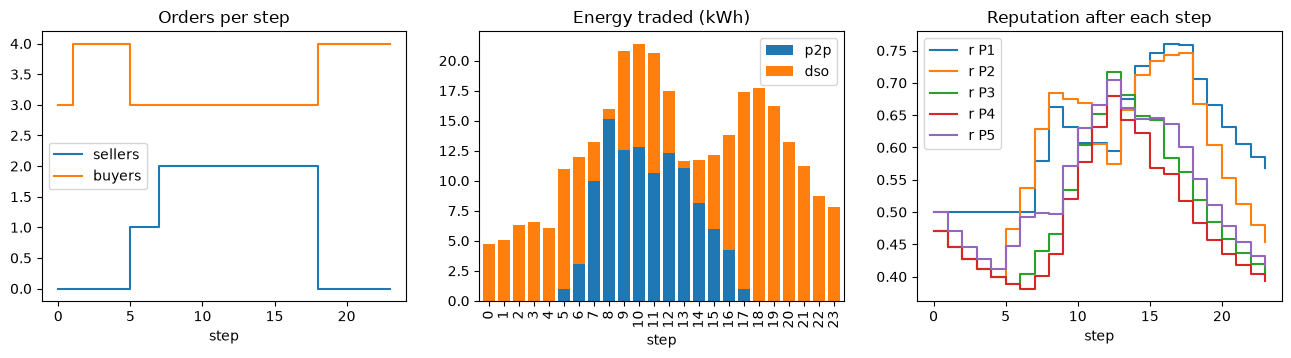

Steps with sellers and buyers: 13 of 24

... of which the best bid reaches the best ask: 13

Peer-to-peer over the day: 107.86 kWh, DSO: 194.76 kWh

In [9]:
fig, (a, b, c) = plt.subplots(1, 3, figsize=(16, 3.5))
day[["sellers", "buyers"]].plot(ax=a, drawstyle="steps-post")
a.set_title("Orders per step")
day[["p2p", "dso"]].plot.bar(ax=b, stacked=True, width=0.8)
b.set_title("Energy traded (kWh)")
day[[col for col in day if col.startswith("r ")]].plot(ax=c, drawstyle="steps-post")
c.set_title("Reputation after each step")
plt.show()

both = day[(day.sellers > 0) & (day.buyers > 0)]
crossing = both[both["best bid"] >= both["best ask"]]
print(f"Steps with sellers and buyers: {len(both)} of {len(day)}")
print(f"... of which the best bid reaches the best ask: {len(crossing)}")
print(f"Peer-to-peer over the day: {day.p2p.sum():.2f} kWh, DSO: {day.dso.sum():.2f} kWh")

**Reading it.** Peers can only trade in a step that has both sellers and buyers,
and only when a bid reaches an ask. If the first count is zero the market has
no counterparty, which is a scenario question (who is placed, batteries), not a
clearing bug. If the second is zero the prices never cross: check `bid_margin`
(below 0.5 for overlap) and the price bounds.

## 5. Checks

Rules every step must keep. Each check prints PASS, or FAIL with the first
steps that break it.

In [10]:
TOL = 1e-6


def check_day(scenario: Scenario, records: list[StepRecord]) -> pd.DataFrame:
    fit, utility = scenario.dso.feed_in_tariff, scenario.dso.utility_price
    kappa = scenario.dso.loss_factor
    batteries = {p.id: p.battery for p in scenario.participants}
    grid = SimBenchGrid(scenario.grid, {})
    buses = {p.id: p.bus for p in scenario.participants}
    failures: dict[str, list[str]] = {}

    def fail(name: str, step: int, text: str) -> None:
        failures.setdefault(name, []).append(f"step {step}: {text}")

    for r in records:
        orders = {o.agent_id: o for o in r.orders}
        # Every order is cleared by the end of stage 3.
        left = r.stages[-1].remaining if r.stages else ()
        if any(o.quantity > TOL for o in left):
            fail("all orders cleared", r.step, f"{len(left)} open")
        for t in r.trades:
            if t.buyer_id == t.seller_id:
                fail("no self-trade", r.step, t.buyer_id)
            dso = DSO_ID in (t.buyer_id, t.seller_id)
            if dso != (t.stage == 3):
                fail("DSO only in stage 3", r.step, f"stage {t.stage}")
            if t.stage == 3:
                want = fit if t.buyer_id == DSO_ID else utility
                if abs(t.price - want) > TOL:
                    fail("DSO pays FiT, charges utility", r.step, f"{t.price}")
                # Its energy runs between the participant and the transformer.
                pid = t.seller_id if t.buyer_id == DSO_ID else t.buyer_id
                km = grid.path_upstream(buses[pid]).distance_km
                if abs(t.distance - km) > TOL or t.fee_parts.zone:
                    fail("DSO trade runs to the transformer", r.step,
                         f"{pid} {t.distance:.4f} km, zone {t.fee_parts.zone}")
            else:
                ask, bid = orders[t.seller_id].price, orders[t.buyer_id].price
                if not ask - TOL <= t.price <= bid + TOL:
                    fail("peer price between ask and bid", r.step,
                         f"{t.price:.4f} not in [{ask:.4f}, {bid:.4f}]")
        # No one trades more than its order, on the order's side.
        for pid, o in orders.items():
            traded = sum(t.quantity for t in r.trades
                         if (t.buyer_id if o.is_buy else t.seller_id) == pid)
            if abs(traded - o.quantity) > TOL:
                fail("traded = order quantity", r.step,
                     f"{pid} traded {traded:.4f} of {o.quantity:.4f}")
        for pid, out in r.participants.items():
            if pid not in orders and (out.bought_kwh or out.sold_kwh):
                fail("no trade without an order", r.step, pid)
            # Demand is satisfied or deferred, never both ways at once.
            if (abs(out.satisfied_demand_kwh + out.deferred_demand_kwh
                    - out.demand_kwh) > TOL
                    or out.deferred_demand_kwh * out.deferred_supply_kwh > TOL):
                fail("satisfied + deferred = demand", r.step, pid)
            # The battery and the trades cover the participant's net position.
            if abs(out.external_kwh) > TOL:
                fail("nothing left untraded", r.step,
                     f"{pid} external {out.external_kwh:.4f} kWh")
            b = batteries[pid]
            if b and out.soc_kwh is not None and not (
                b.min_soc * b.capacity_kwh - TOL
                <= out.soc_kwh
                <= b.max_soc * b.capacity_kwh + TOL
            ):
                fail("battery inside its window", r.step, f"{pid} {out.soc_kwh:.3f}")
        if not r.grid.converged:
            fail("power flow converges", r.step, "did not converge")
        # Money only moves between participants and the DSO.
        paid = sum(o.profit for o in r.participants.values()) + r.dso.profit
        if abs(paid) > TOL:
            fail("money adds up", r.step, f"participants + DSO = {paid:.6f}")
        # Eq. 7: the DSO's balance is what it sold minus what it bought.
        if abs(r.dso.balance_kwh - (r.dso.sold_kwh - r.dso.bought_kwh)) > TOL:
            fail("DSO balance = sold - bought", r.step, f"{r.dso.balance_kwh:.4f}")
        if abs(r.dso.balance_kwh + r.grid_balance_kwh) > TOL:
            fail("DSO balances the market", r.step,
                 f"DSO {r.dso.balance_kwh:.4f}, B_grid {r.grid_balance_kwh:.4f}")
        for t in r.trades:
            # Eq. 18: l = d · q · κ, with the DSO too.
            if abs(t.transmission_loss - t.distance * t.quantity * kappa) > TOL:
                fail("loss = d q kappa", r.step, f"{t.seller_id}->{t.buyer_id}")
            if abs(t.fees - t.fee_parts.total) > TOL:
                fail("fee = sum of its parts", r.step, f"{t.seller_id}->{t.buyer_id}")
            due = t.fees if scenario.dso.fees_charged else 0.0
            if abs(t.buyer_fee + t.seller_fee - due) > TOL:
                fail("fee paid once", r.step, f"{t.seller_id}->{t.buyer_id}")
        for pid, u in r.reputation.items():
            if not -TOL <= u.reputation <= 1 + TOL:
                fail("reputation in 0-1", r.step, f"{pid} {u.reputation:.3f}")

    names = [
        "all orders cleared", "no self-trade", "DSO only in stage 3",
        "DSO pays FiT, charges utility", "DSO trade runs to the transformer",
        "peer price between ask and bid",
        "traded = order quantity", "no trade without an order",
        "satisfied + deferred = demand",
        "nothing left untraded", "battery inside its window", "power flow converges",
        "money adds up", "DSO balance = sold - bought", "DSO balances the market",
        "loss = d q kappa", "fee = sum of its parts", "fee paid once",
        "reputation in 0-1",
    ]
    return pd.DataFrame(
        [
            {
                "check": n,
                "result": "FAIL" if n in failures else "PASS",
                "first failures": "; ".join(failures.get(n, [])[:3]),
            }
            for n in names
        ]
    ).set_index("check")


check_day(scenario, records)

,result,first failures
check,,
all orders cleared,PASS,
no self-trade,PASS,
DSO only in stage 3,PASS,
"DSO pays FiT, charges utility",PASS,
DSO trade runs to the transformer,PASS,
peer price between ask and bid,PASS,
traded = order quantity,PASS,
no trade without an order,PASS,
satisfied + deferred = demand,PASS,


### Partner choice and batteries

Two rules checked on their own, outside a day.

- **Partner choice** ([P1] §3.4): reputation and closeness are both rescaled
  over the candidates, 1 for the best and 0 for the worst, so a weight of 0.5
  gives each the same say. Reputations of 0.50 to 0.56 count as much as
  distances of 0.1 to 0.9 km.
- **Batteries like SimBench's**: a participant that takes over a SimBench storage
  unit gets it as its battery, with its power limit. A battery added elsewhere
  gets capacity ÷ 2 h, the ratio of every SimBench storage unit; `BATTERY_PRESETS`
  are their 10th, 50th and 90th percentile sizes. `set_battery` refuses to
  change a taken-over storage unit's capacity or power; any other battery takes
  its power limit by hand.

In [11]:
from core.market.agent.der import Participant

me = Participant("A", "bus", [], [0.0], [0.0], None)
km = {"near": 0.1, "middle": 0.5, "far": 0.9}
rep = {"near": 0.50, "middle": 0.53, "far": 0.56}
choice = {w: me.choose_partner(list(km), km.get, rep, w) for w in (0.0, 0.5, 0.8, 1.0)}
print("partner by reputation weight:", choice)
assert choice[0.0] == "near" and choice[1.0] == "far"
assert choice[0.5] == "near"  # near 0.5·0 + 0.5·1 = 0.5 = far 0.5·1 + 0.5·0: tie -> nearer
assert choice[0.8] == "far"

b = placement.battery_preset("typical")
print(f"typical battery: {b.capacity_kwh} kWh, {b.max_power_kw} kW")
assert b.max_power_kw == b.capacity_kwh / placement.SIMBENCH_STORAGE_HOURS

future = Scenario(name="storage")
future.grid.code = "1-LV-rural1--2-sw"
print("bus kinds:", placement.kind_counts(future))
placement.place_all(future, ["load", "load+pv", "load+storage"])
owned = [p for p in future.participants if p.battery]
print(f"{len(owned)} of {len(future.participants)} participants took over a SimBench storage:")
display(pd.DataFrame([{"participant": p.id, "bus": p.bus,
                       "capacity kWh": p.battery.capacity_kwh,
                       "power kW": p.battery.max_power_kw} for p in owned]))
assert owned and all(p.battery.max_power_kw > 0 for p in owned)

# A taken-over storage unit's capacity and power are fixed.
try:
    placement.set_battery(future, owned[0].id, placement.battery_preset("small"))
    raise AssertionError("set_battery should refuse")
except ValueError as e:
    print("refused:", e)
p = next(p for p in future.participants if not p.battery)
print(placement.set_battery(future, p.id, BatterySetup(10.0, max_power_kw=4.0)))

partner by reputation weight:

{0.0: 'near', 0.5: 'near', 0.8: 'far', 1.0: 'far'}

typical battery: 13.7 kWh, 6.85 kW

bus kinds:

{'load+pv': 8, 'load+storage': 5}

5 of 13 participants took over a SimBench storage:

,participant,bus,capacity kWh,power kW
0,P2,LV1.101 Bus 10,100.5,50.2
1,P4,LV1.101 Bus 12,146.7,73.4
2,P6,LV1.101 Bus 14,61.1,30.6
3,P10,LV1.101 Bus 6,36.7,18.3
4,P13,LV1.101 Bus 9,67.0,33.5


refused:

P2 took over SimBench storage of 100.5 kWh, 50.2 kW: its capacity and power are fixed

P1: battery saved

## 6. Experiments

Change one thing, play the day again, compare. `compare` takes named scenarios
and returns the day's totals and the checks side by side.

In [12]:
from copy import deepcopy


def compare(**scenarios: Scenario) -> pd.DataFrame:
    rows = {}
    for name, s in scenarios.items():
        recs, d = run_day(s)
        checks = check_day(s, recs)
        rows[name] = {
            "participants": len(s.participants),
            "steps with both sides": int(((d.sellers > 0) & (d.buyers > 0)).sum()),
            "p2p kWh": d.p2p.sum(),
            "dso kWh": d.dso.sum(),
            "fees": d.fees.sum(),
            "dso profit": d["dso profit"].sum(),
            "checks failed": int((checks.result == "FAIL").sum()),
        }
    return pd.DataFrame(rows)


with_loads = deepcopy(scenario)
load_buses = [k for k in placement.kind_counts(with_loads) if "load" in k]
placement.place_all(with_loads, load_buses, battery_kwh=10)

no_batteries = deepcopy(scenario)
for p in no_batteries.participants:
    p.battery = None

high_margin = deepcopy(with_loads)
high_margin.market.bid_margin = 0.6

compare(
    prosumers=scenario,
    every_load_bus=with_loads,
    prosumers_no_battery=no_batteries,
    loads_margin_0_6=high_margin,
)

,prosumers,every_load_bus,prosumers_no_battery,loads_margin_0_6
participants,5.000,13.000,5.000,13.000
steps with both sides,13.000,12.000,13.000,12.000
p2p kWh,107.862,217.426,114.613,0.000
dso kWh,194.761,415.167,199.753,850.018
fees,0.300,0.643,0.161,6.665
dso profit,46.592,61.544,47.950,115.400
checks failed,0.000,0.000,0.000,0.000
